In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from ratingcurve.ratings import PowerLawRating
import numpy as np
import os
from pathlib import Path
import importlib
import rating_curve_DISCHARGE_STAGE_PROBABILITY

importlib.reload(rating_curve_DISCHARGE_STAGE_PROBABILITY)

define_observed_rating_curve = rating_curve_DISCHARGE_STAGE_PROBABILITY.define_observed_rating_curve
plot_rating_curve = rating_curve_DISCHARGE_STAGE_PROBABILITY.plot_rating_curve

In [2]:
script_dir = Path.cwd() 
# Output folder

#Determine Datum offset of Waialua
output_dir = script_dir / "SAVE_DATA"
output_folder =   (  output_dir  / "OBSERVED-rating-curves-results")
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

In [3]:
peaks_dir = script_dir / "SAVE_DATA" / "Stream_Gauge_Annual_Peaks-input"

Waiahole = pd.read_csv( peaks_dir / "Waiahole_weighted_peaks.csv")

Hanalei = pd.read_csv( peaks_dir /"Hanalei_Peaks_63-21_upper-lower-gauges_discharge-height.csv")

Waialua_new = pd.read_csv( peaks_dir /"Waialua_Peaks_05-23.csv")
Waialua_old = pd.read_csv( peaks_dir /"Waialua_Peaks_63-03.csv")


results_folder = output_folder

# Run Rating Curve Model and save figures of curves and modeled data (run only for up to 500 year threshold?

### example of Waiahole

Valid observations: 22
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 42 seconds.
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 5.7609
b[0] = 0.9136, hs[0] = 4.1013
b[1] = 0.3687, hs[1] = 11.9956
b[2] = 0.3886, hs[2] = 13.5603

ln(q) = 5.7609 + 0.9136 * ln(max(h - 4.1013, 0)) + 0.3687 * ln(max(h - 11.9956, 0) + 1) + 0.3886 * ln(max(h - 13.5603, 0) + 1)


Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Waiahole_curve.png


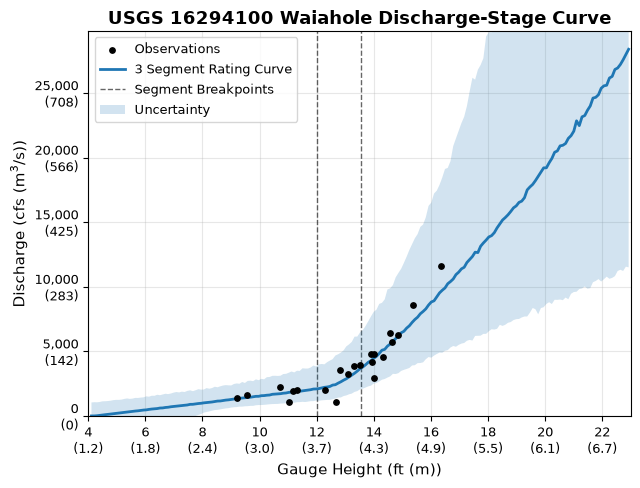

In [16]:
q = Waiahole["peak_va"].values
h = Waiahole["gage_ht"].values

segments = 3
uncertainty_bound = 95
max_discharge = 30000 #end at the 500 year threshold

method = 'nuts' #advi : faster method

Waiahole_curve = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=max_discharge,
    uncertainty_bound=uncertainty_bound,
    method="nuts"
)

fig = plot_rating_curve(
    Waiahole_curve,
    title="USGS 16294100 Waiahole Discharge-Stage Curve",
    figure_name="Waiahole_curve.png"
)



Waiahole_curve['uncertainty_bounds'].to_csv(
    results_folder / "Waiahole_observed_rating_curve_model.csv"
)

Waiahole_curve['observed_data'].to_csv(
    results_folder / "Waiahole_RECORDED_discharge-stage.csv"
)

# example of Hanalei

Valid observations: 40
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 25 seconds.
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 8.5018
b[0] = 0.6510, hs[0] = 4.7703
b[1] = 0.1058, hs[1] = 9.5928
b[2] = 0.0754, hs[2] = 12.2347

ln(q) = 8.5018 + 0.6510 * ln(max(h - 4.7703, 0)) + 0.1058 * ln(max(h - 9.5928, 0) + 1) + 0.0754 * ln(max(h - 12.2347, 0) + 1)


Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Hanalei_curve.png


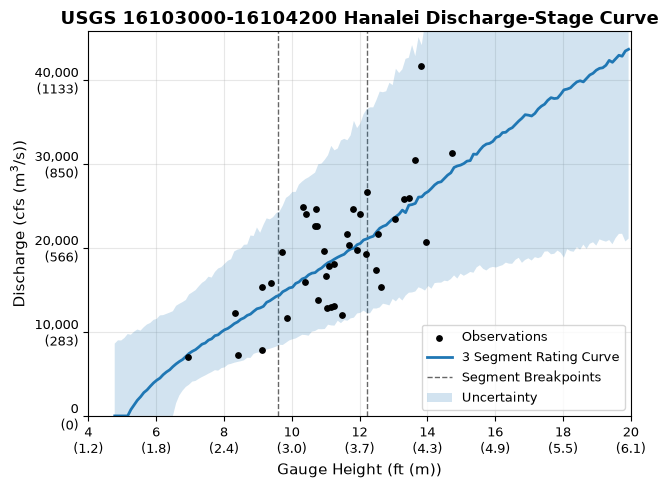

In [5]:

q = Hanalei["Discharge (cfs)"].values
h = Hanalei["Gauge Height (ft)"].values

segments = 3
uncertainty_bound = 95
max_discharge = 46000 #end at the 500 year threshold

method = 'nuts' #advi : faster method

Hanalei_curve = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=max_discharge,
    uncertainty_bound=uncertainty_bound,
    method="nuts"
)

fig = plot_rating_curve(
    Hanalei_curve,
    title="USGS 16103000-16104200 Hanalei Discharge-Stage Curve",
    figure_name="Hanalei_curve.png"
)




Hanalei_curve['uncertainty_bounds'].to_csv(
    results_folder / "Hanalei_observed_rating_curve_model.csv"
)

Hanalei_curve['observed_data'].to_csv(
    results_folder / "Hanalei_RECORDED_discharge-stage.csv"
)

# Adjust the Waialua datum (EXAMPLE Provided)

### include new datum and old datum datasets

Valid observations: 17
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 87 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 3.5418
b[0] = 1.8864, hs[0] = 14.6679
b[1] = 0.2233, hs[1] = 21.3245
b[2] = 0.1616, hs[2] = 24.6669

ln(q) = 3.5418 + 1.8864 * ln(max(h - 14.6679, 0)) + 0.2233 * ln(max(h - 21.3245, 0) + 1) + 0.1616 * ln(max(h - 24.6669, 0) + 1)


Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Waialua_newer_datum_curve.png


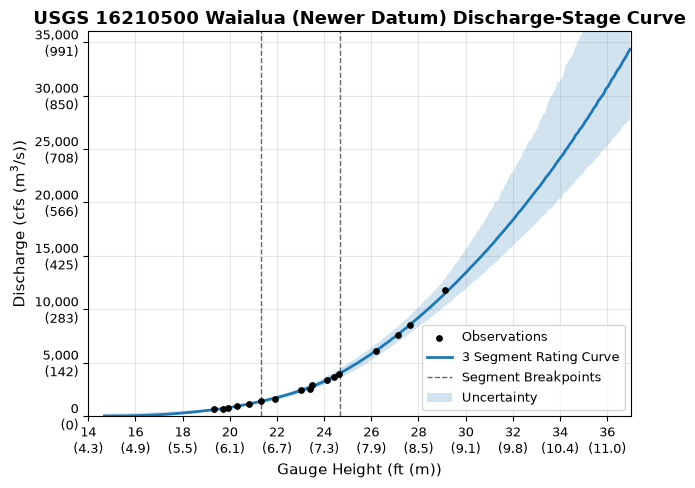

In [6]:


q = Waialua_new["peak_va"].values
h = Waialua_new["gage_ht"].values

segments = 3
uncertainty_bound = 95
max_discharge = 35000 #end at the 500 year threshold

method = 'nuts' #advi : faster method

new_datum_waialua = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=36000,
    uncertainty_bound=95,
    method="nuts"
)

fig = plot_rating_curve(
    new_datum_waialua,
    title="USGS 16210500 Waialua (Newer Datum) Discharge-Stage Curve",
    figure_name="Waialua_newer_datum_curve.png"
)

Valid observations: 31
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 59 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 3.2104
b[0] = 1.8241, hs[0] = 9.7244
b[1] = 0.3181, hs[1] = 19.2968
b[2] = 0.5657, hs[2] = 24.4472

ln(q) = 3.2104 + 1.8241 * ln(max(h - 9.7244, 0)) + 0.3181 * ln(max(h - 19.2968, 0) + 1) + 0.5657 * ln(max(h - 24.4472, 0) + 1)


Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Waialua_older_datum_rating.png


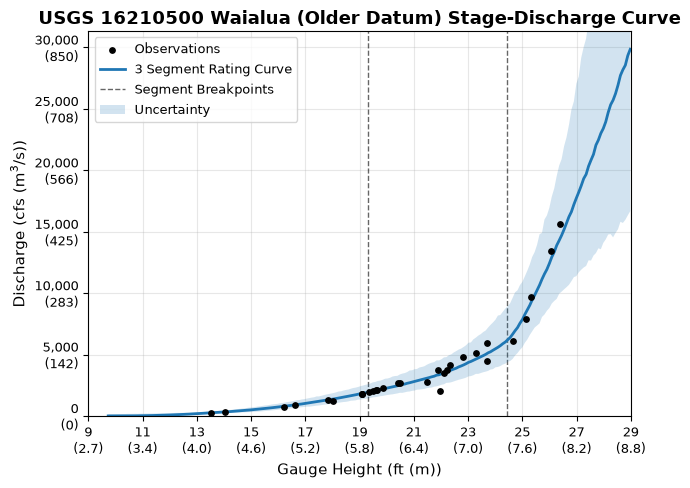

In [7]:
q = Waialua_old["Peak Discharge (cfs)"].values
h = Waialua_old["Gage Height (ft)"].values

segments = 3
uncertainty_bound = 95
max_discharge = 35000 #end at the 500 year threshold

method = 'nuts' #advi : faster method

old_datum_waialua = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=36000,
    uncertainty_bound=95,
    method="nuts"
)

fig = plot_rating_curve(
    old_datum_waialua,
    title="USGS 16210500 Waialua (Older Datum) Stage-Discharge Curve",
    figure_name="Waialua_older_datum_rating.png"
)

old_params = old_datum_waialua["equation_parameters"]
new_params = new_datum_waialua["equation_parameters"]


## calculate differences and plot it to adjust datum

Old observed range: 279 - 15600 cfs
New observed range: 620 - 11800 cfs
Mean datum shift: 2.519 ft
Mean datum shift: 0.768 m
Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Curves_datum_differences.png


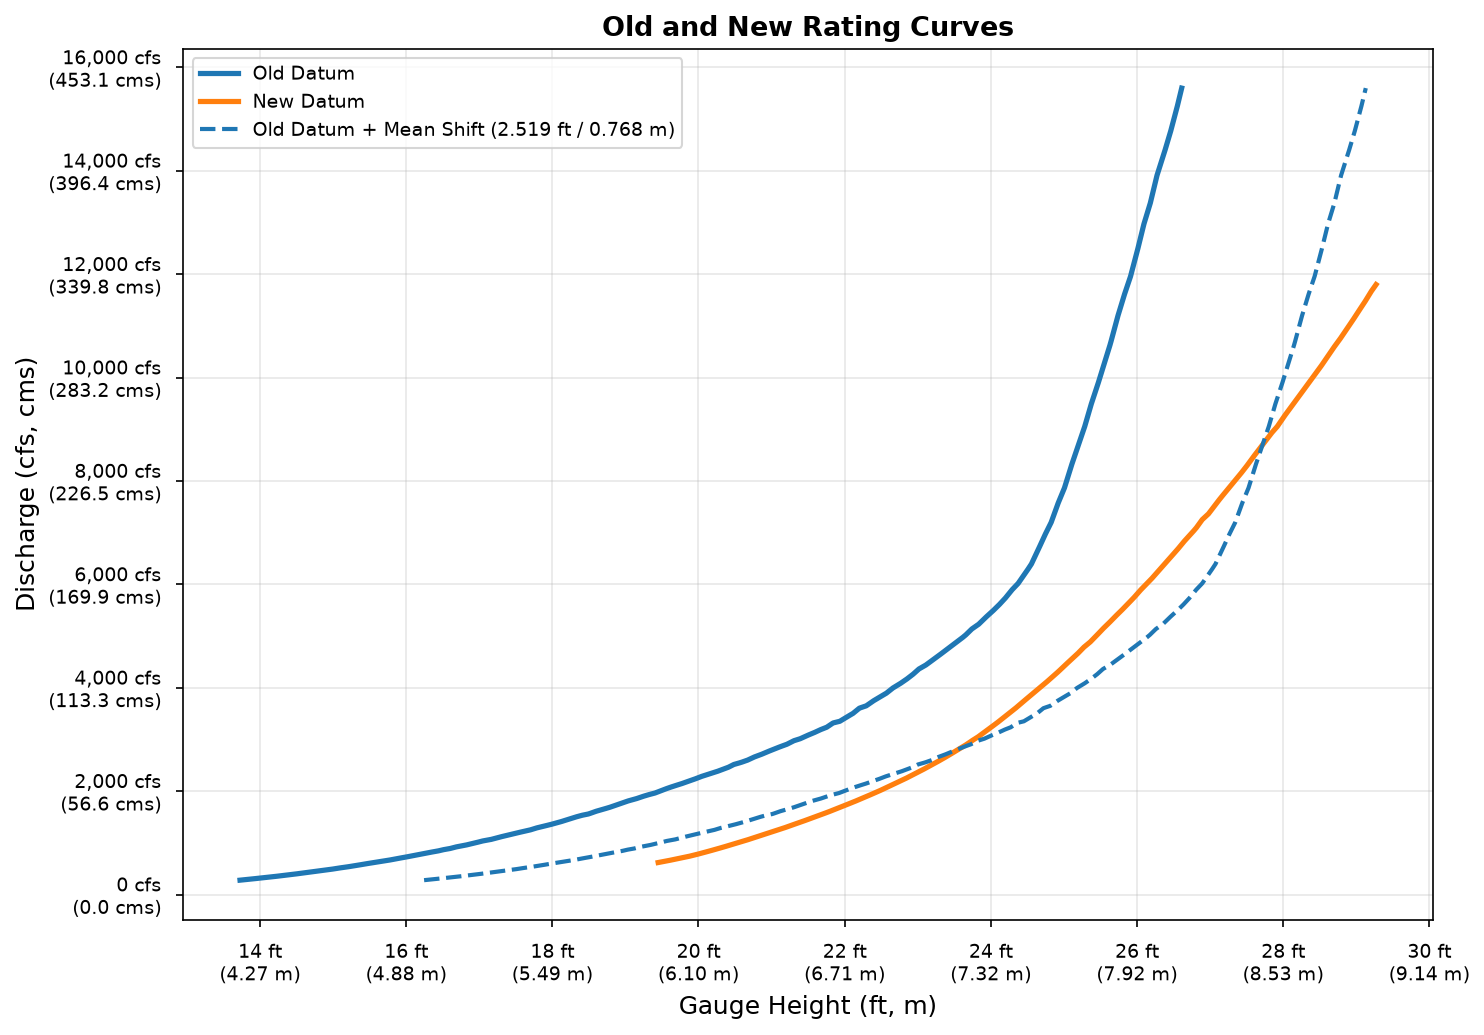

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ============================================================
# GET POSTERIOR MEDIAN CURVES
# ============================================================

old_curve = old_datum_waialua["uncertainty_bounds"]
new_curve = new_datum_waialua["uncertainty_bounds"]

old_h = old_curve["stage_ft"].to_numpy()
old_q = old_curve["median_cfs"].to_numpy()

new_h = new_curve["stage_ft"].to_numpy()
new_q = new_curve["median_cfs"].to_numpy()

# Sort by discharge for interpolation
old_order = np.argsort(old_q)
new_order = np.argsort(new_q)

old_q, old_h = old_q[old_order], old_h[old_order]
new_q, new_h = new_q[new_order], new_h[new_order]

# ============================================================
# OBSERVED DISCHARGE RANGES
# ============================================================

old_obs = old_datum_waialua["observed_data"]
new_obs = new_datum_waialua["observed_data"]

old_min_q = old_obs["discharge"].min()
old_max_q = old_obs["discharge"].max()

new_min_q = new_obs["discharge"].min()
new_max_q = new_obs["discharge"].max()

print(f"Old observed range: {old_min_q:.0f} - {old_max_q:.0f} cfs")
print(f"New observed range: {new_min_q:.0f} - {new_max_q:.0f} cfs")

# ============================================================
# SMOOTH CURVES
# ============================================================

old_q_plot = np.linspace(old_min_q, old_max_q, 2000)
new_q_plot = np.linspace(new_min_q, new_max_q, 2000)

old_stage_plot = np.interp(old_q_plot, old_q, old_h)
new_stage_plot = np.interp(new_q_plot, new_q, new_h)

# ============================================================
# MEAN DATUM SHIFT
# ============================================================

common_min_q = max(old_min_q, new_min_q)
common_max_q = min(old_max_q, new_max_q)

if common_min_q >= common_max_q:
    raise ValueError("Observed discharge ranges do not overlap.")

q_common = np.linspace(common_min_q, common_max_q, 2000)

old_stage_common = np.interp(q_common, old_q, old_h)
new_stage_common = np.interp(q_common, new_q, new_h)

datum_shift = np.mean(new_stage_common - old_stage_common)

print(f"Mean datum shift: {datum_shift:.3f} ft")
print(f"Mean datum shift: {datum_shift * 0.3048:.3f} m")

# ============================================================
# UNIT CONVERSION FORMATTERS
# ============================================================

def format_stage(x, pos):
    return f"{x:g} ft\n({x * 0.3048:.2f} m)"

def format_discharge(y, pos):
    return f"{y:,.0f} cfs\n({y * 0.028316846592:,.1f} cms)"

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

old_color = "tab:blue"
new_color = "tab:orange"

ax.plot(
    old_stage_plot,
    old_q_plot,
    color=old_color,
    linewidth=2.5,
    label="Old Datum"
)

ax.plot(
    new_stage_plot,
    new_q_plot,
    color=new_color,
    linewidth=2.5,
    label="New Datum"
)

ax.plot(
    old_stage_plot + datum_shift,
    old_q_plot,
    color=old_color,
    linestyle="--",
    linewidth=2,
    label=(
        f"Old Datum + Mean Shift "
        f"({datum_shift:.3f} ft / {datum_shift * 0.3048:.3f} m)"
    )
)

# ============================================================
# AXIS LABELS WITH BOTH UNITS
# ============================================================

ax.set_xlabel("Gauge Height (ft, m)", fontsize=12)
ax.set_ylabel("Discharge (cfs, cms)", fontsize=12)

ax.xaxis.set_major_formatter(FuncFormatter(format_stage))
ax.yaxis.set_major_formatter(FuncFormatter(format_discharge))

ax.tick_params(axis="both", labelsize=9, pad=7)

# ============================================================
# FORMATTING
# ============================================================

ax.set_title(
    "Old and New Rating Curves",
    fontsize=13,
    fontweight="bold"
)

ax.grid(alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()

# ============================================================
# SAVE
# ============================================================

figure_folder = os.path.join(os.getcwd(), "figures")
os.makedirs(figure_folder, exist_ok=True)

figure_path = os.path.join(
    figure_folder,
    "Curves_datum_differences.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"Figure saved to: {figure_path}")

plt.show()

Comparison range: 620 - 11800 cfs
Mean difference: 2.519 ft
Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Gauge_datum_differences.png


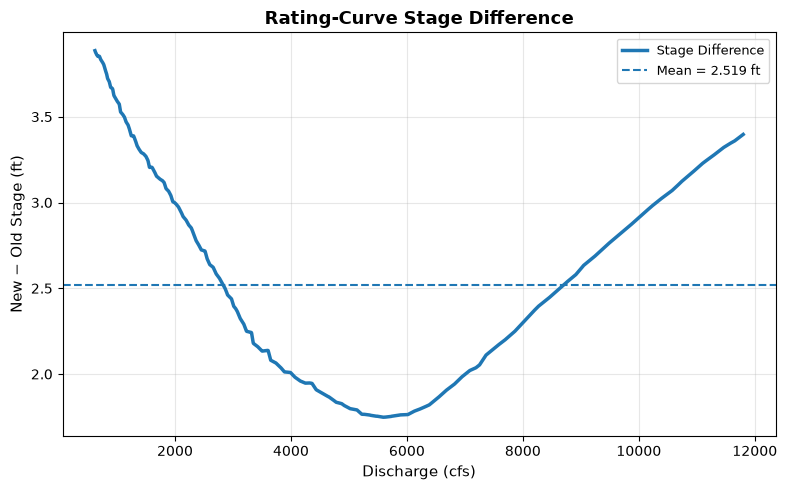

In [9]:
# -----------------------------------
# Smooth stage difference
# New stage - Old stage
# ONLY where observed ranges overlap
# -----------------------------------

old_obs = old_datum_waialua["observed_data"]
new_obs = new_datum_waialua["observed_data"]


# -----------------------------------
# Observed discharge ranges
# -----------------------------------

old_min_q = old_obs["discharge"].min()
old_max_q = old_obs["discharge"].max()

new_min_q = new_obs["discharge"].min()
new_max_q = new_obs["discharge"].max()


# Overlapping observed range
min_discharge = max(
    old_min_q,
    new_min_q
)

max_discharge = min(
    old_max_q,
    new_max_q
)

print(
    f"Comparison range: "
    f"{min_discharge:.0f} - {max_discharge:.0f} cfs"
)


# -----------------------------------
# Common finely spaced discharge values
# -----------------------------------

q_common = np.linspace(
    min_discharge,
    max_discharge,
    2000
)


# -----------------------------------
# Invert smooth posterior curves
# Q -> stage
# -----------------------------------

old_stage_common = np.interp(
    q_common,
    old_q,
    old_h
)

new_stage_common = np.interp(
    q_common,
    new_q,
    new_h
)


# -----------------------------------
# Calculate stage difference
# -----------------------------------

stage_difference = (
    new_stage_common
    - old_stage_common
)

mean_difference = np.mean(
    stage_difference
)

print(
    f"Mean difference: {mean_difference:.3f} ft"
)


# -----------------------------------
# Plot
# -----------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    q_common,
    stage_difference,
    linewidth=2.5,
    label="Stage Difference"
)

ax.axhline(
    mean_difference,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_difference:.3f} ft"
)


# -----------------------------------
# Labels
# -----------------------------------

ax.set_xlabel(
    "Discharge (cfs)",
    fontsize=11
)

ax.set_ylabel(
    "New − Old Stage (ft)",
    fontsize=11
)

ax.set_title(
    "Rating-Curve Stage Difference",
    fontsize=13,
    fontweight="bold"
)

ax.grid(alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()


# -----------------------------------
# Save
# -----------------------------------

figure_name = "Gauge_datum_differences.png"

figure_folder = os.path.join(
    script_dir,
    "figures"
)

os.makedirs(
    figure_folder,
    exist_ok=True
)

figure_path = os.path.join(
    figure_folder,
    figure_name
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"Figure saved to: {figure_path}")

plt.show()

# Apply calculated shift to dataset and calculate rating curve

In [10]:
Waialua_old['datum_shift'] = Waialua_old['Gage Height (ft)'] + mean_difference
Waialua_old['peak_va'] = Waialua_old['Peak Discharge (cfs)']
Waialua_old['peak_dt'] = Waialua_old['Date']
Waialua_old['gage_ht'] = Waialua_old['datum_shift']

In [11]:
# Convert dates BEFORE merging
Waialua_old['peak_dt'] = pd.to_datetime(
    Waialua_old['peak_dt'],
    format='%Y-%m-%d',
    errors='coerce'
)

Waialua_new['peak_dt'] = pd.to_datetime(
    Waialua_new['peak_dt'],
    format='%m/%d/%Y',
    errors='coerce'
)

# Merge
Waialua_merged = pd.concat(
    [
        Waialua_old[['peak_dt', 'peak_va', 'gage_ht']],
        Waialua_new[['peak_dt', 'peak_va', 'gage_ht']]
    ],
    ignore_index=True
)

# Sort
Waialua_merged = (
    Waialua_merged
    .sort_values('peak_dt')
    .reset_index(drop=True)
)


Valid observations: 48
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 50 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 3.6145
b[0] = 1.5162, hs[0] = 12.3551
b[1] = 0.4433, hs[1] = 20.0130
b[2] = 0.4402, hs[2] = 26.2793

ln(q) = 3.6145 + 1.5162 * ln(max(h - 12.3551, 0)) + 0.4433 * ln(max(h - 20.0130, 0) + 1) + 0.4402 * ln(max(h - 26.2793, 0) + 1)


Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Waialua_rating_curve_adjusted_datums.png


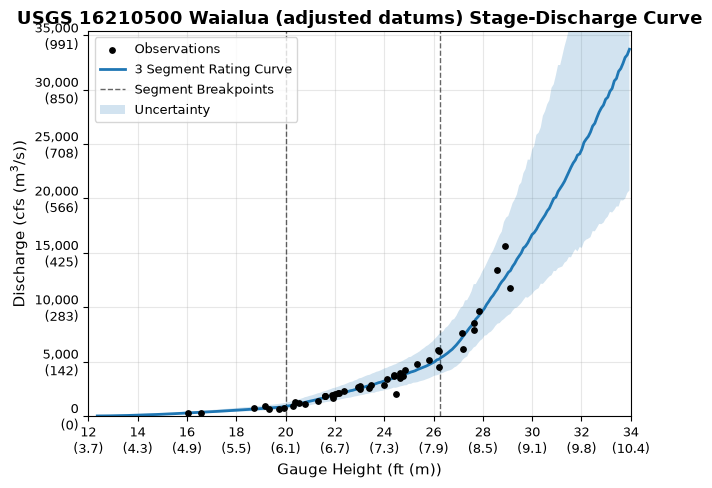

In [12]:
Waialua_DATUM_SHIFT_APPLIED = Waialua_merged

q = Waialua_DATUM_SHIFT_APPLIED["peak_va"].values
h = Waialua_DATUM_SHIFT_APPLIED["gage_ht"].values

segments = 3
uncertainty_bound = 95
max_discharge = 35000 #end at the 500 year threshold

method = 'nuts' #advi : faster method

datum_merged_waialua = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=36000,
    uncertainty_bound=95,
    method="nuts"
)

fig = plot_rating_curve(
    datum_merged_waialua,
    title="USGS 16210500 Waialua (adjusted datums) Stage-Discharge Curve",
    figure_name="Waialua_rating_curve_adjusted_datums.png"
)


In [13]:

datum_merged_waialua['uncertainty_bounds'].to_csv(
    results_folder / "waialua-datum-adjusted_observed_rating_curve_model.csv"
)

datum_merged_waialua['observed_data'].to_csv(
    results_folder / "waialua-datum-adjusted_RECOREDED_discharge-stage.csv"
)